# Assignment 10: Student Habits Analysis


**How to find your place**

Large headings identify the **eight pipeline stages**. Normal-sized bold **Assignment Part** labels retain the original question numbers. Italic **Template section** labels retain the professor's ten starter sections. Each assignment part also shows its pipeline stage and template section.

| Pipeline stage | Assignment parts | Template sections |
| --- | --- | --- |
| Stage 1 · Hold out the test set | 1–3 | 1–3 |
| Stage 2 · Establish a baseline | 4, 5, 18 | 4–5 |
| Stage 3 · Cross-validation | 6 | 6 |
| Stage 4 · Compare models | 7, 8, 19 | 6 |
| Stage 5 · Tune one hyperparameter | 9–12 | 7 |
| Stage 6 · Select a model | 13–14 | 7 |
| Stage 7 · Evaluate once on the test set | 15, 17 | 8 |
| Stage 8 · Analyze errors | 16 | 9 |
| Wrap-up · Conclusion and AI reflection | 20 | 10 |

## Pipeline stage 1 — Hold out the test set

*Assignment Parts 1–3 · Template sections 1–3*

Define the prediction task, choose features, and reserve the final test set.

*Template section 1: Choose your track*

Choose classification (`high_exam_score`) or regression (`exam_score`). Write your prediction scenario.

**Prediction scenario:** Before the final exam, an instructor wants to predict whether a student will score **80 or higher**, using their study habits and background information. This could help identify students who may benefit from additional study support. We use the classification target `high_exam_score`, where `Yes` means a score of at least 80 and `No` means a score below 80. For this scenario, we assume the input features are available before the exam.

**Load and preview the dataset**

In Google Colab, upload `class1_student_habits.csv` using the Files panel before running the notebook. For a local run, keep the CSV in the notebook's working folder.

Preserve the literal `None` as a prior-programming-experience category and treat blank cells as missing values.

In [85]:
import pandas as pd

df = pd.read_csv(
    "class1_student_habits.csv",
    keep_default_na=False,
    na_values=[""],
)
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


**Assignment Part 1: Define the Classification Problem**

*Pipeline stage 1 · Hold out the test set · Template section 1*

Create `high_exam_score` and examine the count and percentage of students in each class. A score of 80 or higher is `Yes`; a score below 80 is `No`.

In [86]:
# Convert the exam-score threshold into Yes/No labels.
df["high_exam_score"] = (df["exam_score"] >= 80).map(
    {True: "Yes", False: "No"}
)

class_counts = df["high_exam_score"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(df) * 100).round(2),
})

display(class_distribution)

,Count,Percentage
high_exam_score,,
No,151,60.4
Yes,99,39.6


*Part 1 — Questions and answers*

1. **What are you trying to predict?**
   We are trying to predict whether a student will have a high exam score, meaning a score of 80 or higher. The target is `high_exam_score`, with the categories `Yes` and `No`.

2. **Why is this a classification problem?**
   This is a classification problem because we are predicting which category a student belongs to: `Yes` or `No`. We are predicting whether their score reaches 80 rather than predicting the exact numerical exam score.

3. **What percentage of students belong to each class?**
   The `No` class contains 151 students, or **60.4%** of the dataset. The `Yes` class contains 99 students, or **39.6%**.

4. **Is the dataset approximately balanced?**
   The dataset is fairly balanced, although the classes are not evenly split. The `No` class is more common, but both classes represent a substantial portion of the dataset.

*Template section 2: Define X and y*

Use legitimate features. Explain excluded columns.

**Assignment Part 2: Select the Features**

*Pipeline stage 1 · Hold out the test set · Template section 2*

Use the seven assigned features as `X` and `high_exam_score` as `y`. Exclude `student_id`, `exam_score`, and `quiz_average` from the input features.

In [87]:
feature_columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

X = df[feature_columns].copy()
y = df["high_exam_score"].copy()

display(X.head())
print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes
0,1.3,7.7,71.8,8,Strong,No,0
1,9.4,6.6,74.2,14,None,Yes,52
2,11.2,6.1,70.3,15,Some,No,7
3,10.8,7.6,77.1,16,Strong,No,12
4,8.0,5.6,89.7,15,None,Yes,12


Feature matrix shape: (250, 7)
Target shape: (250,)


*Part 2 — Questions and answers*

1. **Why would using `exam_score` be target leakage?**
   Using `exam_score` as an input feature would give the model the information that directly determines the answer, because `high_exam_score` is created from whether `exam_score` is at least 80. This could make the model appear to perform very well without learning to predict the category from the student's habits.

2. **Why exclude `student_id`?**

   `student_id` identifies a student but does not describe their habits or background. Including it could encourage the model to learn accidental patterns associated with identifiers that would not generalize to new students. We retain it to identify records during error analysis.

3. **Why exclude `quiz_average`?**

   The assignment specifies seven habit and background features. We exclude `quiz_average` to follow that feature list and investigate how well those features predict high exam scores without another assessment-performance measure. A quiz average available before the exam could be a valid predictor in a different setup; it is not automatically target leakage.

*Template section 3: Train/test split*

Create an 80/20 split. Keep the test set for final evaluation.

**Assignment Part 3: Create the Final Test Set**

*Pipeline stage 1 · Hold out the test set · Template section 3*

Reserve 20% of the data for final testing and use 80% for training and cross-validation. Use `random_state=42` and stratification to preserve approximate class proportions. Keep the test set aside until Part 15, the final test evaluation.

In [88]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training set: {len(X_train)} students")
print(f"Test set: {len(X_test)} students")

# Reserve X_test and y_test until Part 15.
# DataFrame indices are preserved for the later error analysis.

Training set: 200 students
Test set: 50 students


*Part 3 — Questions and answers*

1. **Why are we holding the test set aside?**
   We are holding the test set aside so we can later evaluate the final model on data it has not used for training or model selection. Evaluating on data used to train the model could make the results look better than its performance on new data. Keeping an independent test set helps us estimate how well the model generalizes.

2. **What could happen if we repeatedly check test accuracy while modifying our model?**
   We could start choosing changes that work especially well on this particular test set, causing us to overfit to it even without directly training on it. The test set would then influence model development, so the final test accuracy could look better than the model's performance on new real-world data.

## Pipeline stage 2 — Establish a baseline

*Assignment Parts 4, 5, 18 · Template sections 4–5*

Measure the majority-class baseline, prepare preprocessing, and explain scaling.

*Template section 4: Baseline*

Create a majority-class baseline for classification or mean baseline for regression.

**Assignment Part 5: Establish a Baseline**

*Pipeline stage 2 · Establish a baseline · Template section 4*

Evaluate a majority-class DummyClassifier using five-fold stratified cross-validation on the training data. Report mean CV accuracy and the standard deviation across folds. Reuse this CV splitter for later model comparisons.

In [89]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
)

baseline_summary = pd.DataFrame({
    "Mean CV accuracy": [baseline_cv_scores.mean()],
    "Std. accuracy": [baseline_cv_scores.std()],
}, index=["Majority baseline"])

display(baseline_summary.round(3))

,Mean CV accuracy,Std. accuracy
Majority baseline,0.605,0.01


*Part 5 — Questions and answers*

1. **What does the baseline do?**
   Our baseline always predicts the most common class in its training data. It gives us a simple performance benchmark that our machine-learning models should improve on.

2. **What is its mean CV accuracy?**
   The baseline's mean CV accuracy is **60.5%**, with a standard deviation of **1 percentage point** across the five folds.

3. **Why should our machine-learning models be compared with this baseline?**
   We compare them to determine whether using the student features improves performance over simply predicting the majority class. A model that performs similarly to the baseline provides little improvement in accuracy.

*Template section 5: Preprocessing pipeline*

Handle missing values and categorical variables.

**Assignment Part 4: Build the Preprocessing Pipeline**

*Pipeline stage 2 · Establish a baseline · Template section 5*

Prepare numerical features with median imputation followed by standardization. The median is less sensitive to extreme values than the mean. Prepare categorical features with most-frequent-category imputation followed by one-hot encoding. This fills missing categories using an existing training category. Combine these steps using a ColumnTransformer and learn all preprocessing inside each CV training fold.

In [90]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
]

categorical_features = [
    "prior_programming_experience",
    "study_group",
]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features),
])

*Part 4 — Questions and answers*

1. **Why should preprocessing be included inside the pipeline?**
   Preprocessing should be included so the same steps are applied consistently. Values such as imputation medians and scaling statistics should be learned only from training data, preventing information from validation or test data from leaking into training.

2. **Why is this especially important when using cross-validation?**
   Each fold needs preprocessing fitted using only its training portion. Its validation portion is then transformed using those learned settings. This keeps the validation results independent and makes comparisons fair.

3. **Which of the models in this assignment are sensitive to feature scaling?**
   Logistic Regression is sensitive to feature scaling because different feature scales can affect its optimization and regularization.

4. **Do Decision Trees and Random Forests generally require scaling?**
   They generally do not require scaling because they use threshold splits. Scaling changes the numerical thresholds but preserves the ordering of observations, so the same splits remain possible.

**Assignment Part 18: Scaling and Different Models**

*Pipeline stage 2 · Establish a baseline · Template section 5*

*Part 18 — Questions and answers*

1. **Why is scaling useful for Logistic Regression?**
   Scaling puts numerical features on comparable scales, helping the model's training process converge. It also makes regularization—the penalty used to limit large coefficients—less dependent on the units used to measure each feature. Scaling can help optimization without necessarily improving validation accuracy, as the experiment in Part 19 illustrates.

2. **Why do Decision Trees generally not require scaling?**
   Decision Trees choose threshold splits based on the ordering of feature values. Standardization changes the values and numerical thresholds but preserves their ordering, so the same groups of observations can still be separated.

3. **Why do Random Forests generally not require scaling?**
   Random Forests combine many Decision Trees. Since those trees use threshold splits that preserve the same possible partitions after standardization, Random Forests generally do not require scaling either.

For the assignment's **`attendance_rate < 85` example**, standardization would replace 85 with an equivalent threshold in standardized units. The same students would fall on each side of the split.

## Pipeline stage 3 — Cross-validation

*Assignment Parts 6 · Template section 6*

Understand how training and validation rotate through five folds.

*Template section 6: Cross-validation comparison*

Compare a small set of models using the same folds and metrics.

**Assignment Part 6: Understand Cross-Validation**

*Pipeline stage 3 · Cross-validation · Template section 6*

Use the CV splitter from Part 5 to display the training and validation sizes for each fold.

In [91]:
fold_summary = []

for fold_number, (train_indices, validation_indices) in enumerate(
    cv.split(X_train, y_train),
    start=1,
):
    fold_summary.append({
        "Fold": fold_number,
        "Training students": len(train_indices),
        "Validation students": len(validation_indices),
    })

display(pd.DataFrame(fold_summary))

,Fold,Training students,Validation students
0,1,160,40
1,2,160,40
2,3,160,40
3,4,160,40
4,5,160,40


*Part 6 — Questions and answers*

1. **What happens during five-fold cross-validation?**
   The training data is divided into five parts. Each run trains the model on four parts and evaluates it on the remaining validation part. This repeats five times, changing which part is used for validation so every observation appears in validation once.

2. **How many times is each model trained?**
   Each model is trained **five times**, once for each validation fold. Each run uses four folds for training and one for validation.

3. **Why is cross-validation more informative than evaluating a model using only one training/validation split?**
   It gives us a better understanding of how the model performs across different portions of the data. Instead of depending on one trial, we can compare the average performance and variation across five validation results.

4. **Why do we still keep a separate final test set?**
   We keep a separate test set so our final evaluation uses data that has not influenced training, model comparison, or hyperparameter selection. This prevents test information from leaking into model development and helps us estimate performance on new data.

## Pipeline stage 4 — Compare models

*Assignment Parts 7, 8, 19 · Template section 6*

Compare classifiers and run the controlled scaling experiment using training-data CV.

**Assignment Part 7: Compare Three Classification Models**

*Pipeline stage 4 · Compare models · Template section 6*

Create Logistic Regression, a Decision Tree with `max_depth=4`, and a Random Forest with 200 trees. Give each model an independent copy of the preprocessing pipeline and include the majority baseline for comparison.

In [92]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
    ),
}

models = {"Majority baseline": baseline_model}

for model_name, classifier in classifiers.items():
    models[model_name] = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier),
    ])

**Assignment Part 8: Compare the Models with Cross-Validation**

*Pipeline stage 4 · Compare models · Template section 6*

Evaluate all four classifiers using the same five-fold CV splitter on the training data. Report mean accuracy, standard deviation of accuracy, mean precision, and mean recall, with `Yes` as the positive class. The returned `test_*` fields refer to CV validation scores; the held-out test set remains reserved. Undefined precision is reported as zero using `zero_division=0`.

In [93]:
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes", zero_division=0
    ),
}

comparison_rows = []
cv_results = {}

for model_name, model in models.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise",
    )

    cv_results[model_name] = results

    comparison_rows.append({
        "Model": model_name,
        "Mean CV Accuracy": results["test_accuracy"].mean(),
        "Std. Accuracy": results["test_accuracy"].std(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(3))

,Model,Mean CV Accuracy,Std. Accuracy,Precision,Recall
0,Majority baseline,0.605,0.010,0.000,0.000
1,Logistic Regression,0.740,0.064,0.728,0.571
2,Decision Tree,0.670,0.040,0.598,0.493
3,Random Forest,0.690,0.072,0.642,0.518


*Part 8 — Questions and answers*

1. **Which model has the highest mean CV accuracy?**
   Logistic Regression has the highest mean CV accuracy at **74.0%**.

2. **How large are the differences?**
   Logistic Regression is **7 percentage points** ahead of Decision Tree and **5 points** ahead of Random Forest. Random Forest is **2 points** ahead of Decision Tree. The largest overall difference is **13.5 points**, between Logistic Regression and the majority baseline.

3. **Which model has the highest recall?**
   Logistic Regression has the highest recall at **57.1%**, compared with **51.8%** for Random Forest and **49.3%** for Decision Tree.

4. **Do all metrics identify the same model?**
   Accuracy, precision, and recall all favor Logistic Regression. However, Decision Tree has less variation across folds than the other two machine-learning models, so the ranking differs when considering consistency.

5. **How much does performance vary between folds?**
   There is noticeable variation. Accuracy standard deviations are **6.4 percentage points** for Logistic Regression, **4.0** for Decision Tree, and **7.2** for Random Forest. The baseline varies by **1.0 point**. Because the differences between models are modest relative to this variation, we should avoid claiming that the highest average score proves a model is definitely better.

**Assignment Part 19: Design One Controlled Experiment**

*Pipeline stage 4 · Compare models · Template section 6*

**Hypothesis (written before running the experiment):** I expect Logistic Regression's mean cross-validation accuracy to decrease when scaling is removed because differences in numerical feature scales may affect optimization and regularization.

Compare Logistic Regression with and without numerical scaling. Keep the features, missing-value handling, categorical encoding, classifier settings, CV folds, and scoring rules fixed. Use only training-data cross-validation.

In [94]:
scaled_model = clone(models["Logistic Regression"])
unscaled_model = clone(models["Logistic Regression"])

# Skip only the numerical scaling step.
unscaled_model.set_params(
    preprocessor__numerical__scaler="passthrough"
)

scaling_models = {
    "With scaling": scaled_model,
    "Without scaling": unscaled_model,
}

scaling_rows = []
scaling_cv_results = {}

for setting, model in scaling_models.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise",
    )

    scaling_cv_results[setting] = results

    scaling_rows.append({
        "Setting": setting,
        "Mean CV Accuracy": results["test_accuracy"].mean(),
        "Std. Accuracy": results["test_accuracy"].std(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
    })

scaling_comparison = pd.DataFrame(scaling_rows)
display(scaling_comparison.round(3))

,Setting,Mean CV Accuracy,Std. Accuracy,Precision,Recall
0,With scaling,0.740,0.064,0.728,0.571
1,Without scaling,0.745,0.064,0.732,0.583


**Supporting calculation — Part 19: solver iterations**

Fit independent copies of the scaled and unscaled pipelines on all 200 training students. Report solver iterations and convergence warnings. These fits are separate from the CV evaluation and use training data only.

In [95]:
import warnings
from sklearn.exceptions import ConvergenceWarning

solver_rows = []

for setting, model in scaling_models.items():
    diagnostic_model = clone(model)

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        diagnostic_model.fit(X_train, y_train)

    solver_rows.append({
        "Setting": setting,
        "Training students": len(X_train),
        "Solver iterations":
            int(diagnostic_model.named_steps["classifier"].n_iter_[0]),
        "Convergence warning": any(
            issubclass(w.category, ConvergenceWarning) for w in caught
        ),
    })

solver_summary = pd.DataFrame(solver_rows)
display(solver_summary)

,Setting,Training students,Solver iterations,Convergence warning
0,With scaling,200,14,False
1,Without scaling,200,456,False


*Part 19 — Experiment discussion*

The assignment requires an experiment write-up. These responses describe the design, report the results, and interpret whether they support the hypothesis.

1. **What did you change, and what did you keep fixed?**
   We changed whether numerical features were scaled. We kept the features, missing-value handling, categorical encoding, model settings, scoring rules, and CV folds fixed.

2. **What were the results with and without scaling?**
   Mean CV accuracy was **74.0% with scaling** and **74.5% without scaling**. The scaled model correctly classified **148 of 200 validation predictions**, compared with **149 of 200 without scaling**. Each of the 200 training students received one validation prediction across the five equally sized folds.

3. **Do the results support your hypothesis? Explain.**
   No. We expected accuracy to decrease without scaling, but it increased slightly by **0.5 percentage points**.

4. **What can you conclude given the size of the difference and the variation across folds?**
   The average accuracy difference was only **0.5 percentage points**, representing just **one additional correct validation prediction**, while the standard deviation across folds was approximately **6.4 points** for both versions. Their performance was similar, so we should avoid claiming that removing scaling provides a clear accuracy advantage based on this small difference.

   Scaling did affect optimization. In a follow-up diagnostic fit of each version on all **200 training students**, the scaled model required **14 solver iterations**, compared with **456 without scaling** in our current environment. Both converged without a convergence warning within the 1,000-iteration limit. These are full-training-fit counts from the classifier's [`n_iter_` attribute](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LogisticRegression.html), rather than averages across CV folds. Scaling helped the solver reach convergence in fewer iterations even though CV accuracy was nearly identical. This reconciles the explanation in Part 18 with the small accuracy difference in this experiment.

The supporting solver table is a diagnostic fit on all training students; its iteration counts can vary across library versions and numerical environments. The experiment measures the overall effect of scaling under fixed model settings. Scaling affects regularization as well as optimization, and fewer solver iterations do not by themselves establish a measured training-time improvement.

## Pipeline stage 5 — Tune one hyperparameter

*Assignment Parts 9–12 · Template section 7*

Investigate tree depth and identify underfitting and overfitting.

*Template section 7: Tune one hyperparameter*

Tune decision-tree max_depth using cross-validation on the training data.

**Assignment Part 9: Hyperparameters**

*Pipeline stage 5 · Tune one hyperparameter · Template section 7*

*Part 9 — Questions and answers*

1. **Explain the difference between a learned model parameter and a chosen hyperparameter in your own words, using Decision Tree max_depth as the example.**

   A model parameter is learned from the training data, such as a Decision Tree's split thresholds and predictions at its leaves. An input variable such as attendance is a feature.

   A hyperparameter is a setting chosen before training, such as `max_depth` or a limit on the number of leaves. `max_depth` controls how complex the tree is allowed to become.

**Assignment Part 10: Experiment with Decision-Tree Depth**

*Pipeline stage 5 · Tune one hyperparameter · Template section 7*

Evaluate the seven assigned depth settings using the same preprocessing and five-fold CV procedure on training data. Collect training and validation accuracy from each CV fit, then report mean training accuracy, mean CV accuracy, and the standard deviation of CV accuracy.

In [96]:
depths = [1, 2, 3, 4, 6, 8, None]

depth_rows = []
depth_cv_results = {}

for depth in depths:
    model = clone(models["Decision Tree"])
    model.set_params(classifier__max_depth=depth)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        return_train_score=True,
        error_score="raise",
    )

    depth_cv_results[depth] = scores

    depth_rows.append({
        "max_depth": str(depth),
        "Training Accuracy": scores["train_score"].mean(),
        "CV Accuracy": scores["test_score"].mean(),
        "CV Std.": scores["test_score"].std(),
    })

depth_table = pd.DataFrame(depth_rows)
display(depth_table.round(3))

,max_depth,Training Accuracy,CV Accuracy,CV Std.
0,1,0.661,0.560,0.066
1,2,0.712,0.625,0.057
2,3,0.772,0.610,0.051
3,4,0.826,0.670,0.040
4,6,0.925,0.615,0.056
5,8,0.979,0.620,0.043
6,None,1.000,0.595,0.060


**Assignment Part 11: Visualize Model Complexity**

*Pipeline stage 5 · Tune one hyperparameter · Template section 7*

Plot mean training accuracy and mean CV accuracy for the evaluated depth settings. Label `None` as the unlimited-depth case.

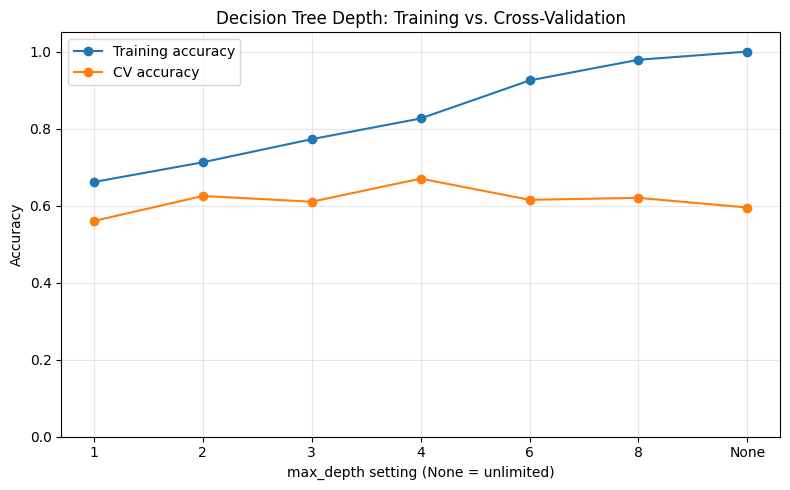

In [97]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    depth_table["max_depth"],
    depth_table["Training Accuracy"],
    marker="o",
    label="Training accuracy",
)

ax.plot(
    depth_table["max_depth"],
    depth_table["CV Accuracy"],
    marker="o",
    label="CV accuracy",
)

ax.set_title("Decision Tree Depth: Training vs. Cross-Validation")
ax.set_xlabel("max_depth setting (None = unlimited)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

*Part 11 — Questions and answers*

1. **What happens to training accuracy as max_depth increases?**

   Training accuracy increases because the tree can make more splits and fit the training data more closely. It rises from 66.1% at depth 1 to 100% with unlimited depth.

2. **What happens to cross-validation accuracy?**

   CV accuracy fluctuates. It reaches its highest value at depth 4, then remains below that peak for deeper trees even though training accuracy continues increasing.

3. **At what depth does the tree appear to perform best on unseen data, based on CV?**

   Depth 4 has the highest mean CV accuracy among the tested settings, at 67.0%.

4. **Do you see evidence of underfitting?**

   Yes. Depth 1 appears too simple, with 66.1% training accuracy and 56.0% CV accuracy. Its mean CV accuracy is below the majority baseline's 60.5%, which always predicts `No`.

5. **Do you see evidence of overfitting?**

   Yes. The deeper trees perform much better on training data than validation data. The unlimited tree (`max_depth=None`) reaches 100% training accuracy, but only 59.5% CV accuracy, also below the majority baseline's 60.5%. This illustrates how fitting the training data perfectly can still produce poor validation performance.

**Assignment Part 12: Understand Underfitting and Overfitting**

*Pipeline stage 5 · Tune one hyperparameter · Template section 7*

*Part 12 — Questions and answers*

1. **Which Decision Tree depth appears to underfit?**

   Depth 1 appears too simple, with 66.1% training accuracy and 56.0% CV accuracy. Its mean CV accuracy is below the majority baseline's 60.5%, which always predicts `No`.

2. **Which depth appears to generalize best?**

   Depth 4 appears to generalize best among the tested depths because it has the highest mean CV accuracy, at 67.0%.

3. **Do the deepest trees show signs of overfitting?**

   Yes. The deeper trees perform much better on training data than validation data. The unlimited tree (`max_depth=None`) reaches 100% training accuracy, but only 59.5% CV accuracy, also below the majority baseline's 60.5%. This illustrates how fitting the training data perfectly can still produce poor validation performance.

4. **Why should we not simply choose the tree with the highest training accuracy?**

   We should not simply choose the model with the highest training accuracy because it may overfit the training data. Cross-validation accuracy gives us a better estimate of how it generalizes to unseen data. We use those results to select the model, then evaluate it once on the held-out test set.

## Pipeline stage 6 — Select a model

*Assignment Parts 13–14 · Template section 7*

Choose a tree depth and the final classifier using CV results.

**Assignment Part 13: Select a Decision-Tree Depth**

*Pipeline stage 6 · Select a model · Template section 7*

In [98]:
selected_depth = 4

*Part 13 — Questions and answers*

1. **Why did you choose this depth? Discuss mean CV performance, variability, and model complexity.**

   I choose `max_depth=4` because it has the highest mean CV accuracy at 67.0% and the lowest CV standard deviation among the tested depths at 4.0 percentage points. It allows the tree to capture useful patterns while limiting complexity. Deeper trees have higher training accuracy but lower CV accuracy, which suggests overfitting.

**Assignment Part 14: Compare the Tuned Tree Again**

*Pipeline stage 6 · Select a model · Template section 7*

Evaluate the selected depth using the same five-fold CV and add the tuned tree to the comparison table. The original and tuned trees both use `max_depth=4`, so they have the same settings and produce identical CV results.

In [99]:
tuned_tree = clone(models["Decision Tree"])
tuned_tree.set_params(classifier__max_depth=selected_depth)

tuned_cv_results = cross_validate(
    tuned_tree,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise",
)

tuned_row = {
    "Model": "Tuned Decision Tree",
    "Mean CV Accuracy": tuned_cv_results["test_accuracy"].mean(),
    "Std. Accuracy": tuned_cv_results["test_accuracy"].std(),
    "Precision": tuned_cv_results["test_precision"].mean(),
    "Recall": tuned_cv_results["test_recall"].mean(),
}

updated_rows = comparison_rows.copy()
updated_rows.insert(3, tuned_row)

updated_comparison_table = pd.DataFrame(updated_rows)
updated_comparison_table["Model"] = (
    updated_comparison_table["Model"].replace(
        {"Decision Tree": "Original Decision Tree"}
    )
)

display(updated_comparison_table.round(3))

,Model,Mean CV Accuracy,Std. Accuracy,Precision,Recall
0,Majority baseline,0.605,0.010,0.000,0.000
1,Logistic Regression,0.740,0.064,0.728,0.571
2,Original Decision Tree,0.670,0.040,0.598,0.493
3,Tuned Decision Tree,0.670,0.040,0.598,0.493
4,Random Forest,0.690,0.072,0.642,0.518


*Part 14 — Questions and answers*

1. **Based only on the training-data cross-validation results, which model would you carry forward to final evaluation? Explain your reasoning.**

   I would carry Logistic Regression with scaling forward to final evaluation because it has the highest mean CV accuracy (74.0%), precision (72.8%), and recall (57.1%) in the original model-comparison table. Although the Decision Tree varies less across folds, Logistic Regression has stronger average predictive performance. These results support choosing it, but do not guarantee it will perform best on future data.

   Although unscaled Logistic Regression achieved 74.5% mean CV accuracy, its 0.5 percentage-point advantage represented only one additional correct validation prediction. I retained the scaled pipeline because this small difference did not provide clear evidence of an advantage, and scaling supports optimization and regularization across features measured in different units.

The final model uses the existing preprocessing pipeline and `LogisticRegression(max_iter=1000, random_state=42)`. This choice is recorded before evaluating the held-out test set.

In [100]:
final_model_name = "Logistic Regression"
final_model = clone(models[final_model_name])
final_cv_results = cv_results[final_model_name]

print(f"Selected model: {final_model_name}")

Selected model: Logistic Regression


## Pipeline stage 7 — Evaluate once on the test set

*Assignment Parts 15, 17 · Template section 8*

Evaluate the selected model and explain why the test set stays independent.

*Template section 8: Final test evaluation*

Choose one workflow, fit on full training data, and evaluate once on the test set.

**Assignment Part 15: Final Test Evaluation**

*Pipeline stage 7 · Evaluate once on the test set · Template section 8*

Fit the selected scaled Logistic Regression pipeline on the complete training set. Evaluate it on the held-out test set and save the predictions for all metrics and later error analysis. Keep the selected model and settings fixed after this evaluation.

In [101]:
from sklearn.metrics import accuracy_score, confusion_matrix

final_model.fit(X_train, y_train)

test_predictions = pd.Series(
    final_model.predict(X_test),
    index=X_test.index,
    name="Predicted",
)

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, pos_label="Yes", zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, pos_label="Yes", zero_division=0
    ),
}

cv_metrics = {
    "Accuracy": final_cv_results["test_accuracy"].mean(),
    "Precision": final_cv_results["test_precision"].mean(),
    "Recall": final_cv_results["test_recall"].mean(),
}

evaluation_table = pd.DataFrame(
    [cv_metrics, test_metrics],
    index=["Mean CV", "Final test"],
)

display(evaluation_table.round(3))

majority_class = y_train.value_counts().idxmax()
baseline_test_accuracy = (y_test == majority_class).mean()

print(
    f"Majority-class test accuracy: {baseline_test_accuracy:.1%} "
    f"(always predicting {majority_class})"
)

test_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        y_test,
        test_predictions,
        labels=["No", "Yes"],
    ),
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"],
)

display(test_confusion_matrix)

,Accuracy,Precision,Recall
Mean CV,0.74,0.728,0.571
Final test,0.84,0.875,0.700


Majority-class test accuracy: 60.0% (always predicting No)


,Predicted No,Predicted Yes
Actual No,28,2
Actual Yes,6,14


**Supporting calculation — Part 15: accuracy uncertainty**

Reuse the saved final test predictions to calculate an exact 95% Clopper–Pearson binomial confidence interval for accuracy. The interval assumes independent, representative observations; it is not a guarantee of performance for another student population.

In [102]:
from scipy.stats import binomtest

correct_predictions = int((test_predictions == y_test).sum())
accuracy_interval = binomtest(
    correct_predictions, len(y_test)
).proportion_ci(confidence_level=0.95, method="exact")

print(f"Correct predictions: {correct_predictions}/{len(y_test)}")
print(
    f"Exact 95% accuracy interval: "
    f"{accuracy_interval.low:.1%}–{accuracy_interval.high:.1%}"
)

Correct predictions: 42/50
Exact 95% accuracy interval: 70.9%–92.8%


*Part 15 — Questions and answers*

1. **How does final test accuracy compare with mean CV accuracy?**

   The model correctly classified 42 of 50 test students, giving final test accuracy of 84.0%, compared with mean CV accuracy of 74.0%, an increase of 10 percentage points.

2. **Is it reasonably consistent with what you observed during cross-validation?**

   Yes. For 42 correct predictions out of 50 test students, the exact 95% binomial confidence interval for accuracy is approximately **70.9%–92.8%**, using the [Clopper–Pearson exact method](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html). This interval contains the **74.0% CV mean**, so the higher test result is reasonably compatible with our CV results. I would use 74.0% as a more conservative working expectation because cross-validation covers 200 students, while the test result comes from only 50.

3. **Did the model outperform the majority-class baseline?**

   Yes. The model achieved 84.0% test accuracy, compared with 60.0% for the majority-class baseline, a difference of 24 percentage points.

4. **Are precision and recall similar to the CV results?**

   Both were higher on the test set, with noticeable differences. Precision increased from 72.8% to 87.5%, and recall increased from 57.1% to 70.0%.

**Assignment Part 17: Why Didn't We Tune Using the Test Set?**

*Pipeline stage 7 · Evaluate once on the test set · Template section 8*

Consider repeatedly checking test accuracy while trying different models and changing hyperparameters, then choosing whichever result is highest. Compare this procedure with training-data cross-validation, model comparison, tuning, selection, and one final test evaluation.

*Part 17 — Questions and answers*

1. **What is wrong with repeatedly checking test accuracy while comparing models and changing hyperparameters?**

   It can cause us to choose models and settings that perform especially well on that particular test set, producing an overly optimistic estimate of performance on new data.

2. **How has the test set indirectly become part of model development?**

   Changes are made based on its results, so the test set influences how we design and select our models, even though we do not directly train on it.

3. **Why is the final test score no longer a completely independent evaluation?**

   The test results have already influenced our model choices. Evaluating those choices on the same data no longer provides an independent assessment.

4. **Why is training-data CV → comparison → tuning → selection → final test evaluation preferable?**

   We use training-data cross-validation to compare models, tune settings, and select the final model. We then keep that choice fixed and evaluate it on the held-out test set. This preserves a more independent estimate of performance on unseen data.

## Pipeline stage 8 — Analyze errors

*Assignment Parts 16 · Template section 9*

Inspect the saved final predictions and describe patterns among mistakes.

*Template section 9: Error analysis*

Classification: false positives/false negatives. Regression: largest residuals.

**Assignment Part 16: Analyze the Final Errors**

*Pipeline stage 8 · Analyze errors · Template section 9*

Reuse the saved test predictions to identify false positives and false negatives. Display the original feature values, student IDs, actual labels, and predictions for the incorrectly classified students. Interpret descriptive patterns as possible explanations rather than causal conclusions.

In [103]:
test_results = X_test.copy()

test_results.insert(
    0,
    "student_id",
    df.loc[X_test.index, "student_id"],
)

test_results["Actual"] = y_test
test_results["Predicted"] = test_predictions

false_positive_mask = (
    (test_results["Actual"] == "No")
    & (test_results["Predicted"] == "Yes")
)

false_negative_mask = (
    (test_results["Actual"] == "Yes")
    & (test_results["Predicted"] == "No")
)

test_results["Error type"] = "Correct"
test_results.loc[false_positive_mask, "Error type"] = "False positive"
test_results.loc[false_negative_mask, "Error type"] = "False negative"

error_counts = pd.DataFrame({
    "Error type": ["False positive", "False negative"],
    "Count": [
        false_positive_mask.sum(),
        false_negative_mask.sum(),
    ],
})

display(error_counts)

errors = test_results.loc[
    false_positive_mask | false_negative_mask
].copy()

print(
    f"Total incorrect predictions: {len(errors)} "
    f"out of {len(test_results)}"
)

display(errors.sort_values(["Error type", "student_id"]))

,Error type,Count
0,False positive,2
1,False negative,6


Total incorrect predictions: 8 out of 50


,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,Actual,Predicted,Error type
37,S038,5.5,7.1,78.3,22,Some,Yes,19,Yes,No,False negative
80,S081,5.6,7.6,87.3,36,None,No,28,Yes,No,False negative
89,S090,NaN,6.2,72.7,15,Strong,No,28,Yes,No,False negative
99,S100,5.7,7.2,82.7,19,NaN,No,14,Yes,No,False negative
113,S114,10.3,6.0,89.5,9,Some,No,38,Yes,No,False negative
140,S141,9.4,7.0,82.8,13,Some,No,31,Yes,No,False negative
132,S133,9.7,5.7,92.9,13,Some,Yes,0,No,Yes,False positive
169,S170,9.4,7.5,98.3,19,None,No,45,No,Yes,False positive


**Supporting calculations — Part 16: cutoff and missing values**

Inspect `exam_score` after prediction in a separate diagnostic table. It remains excluded from the model features. Compare errors within five points of 80 with errors outside that range, and count students with missing predictor values. `Error_rate` is a proportion, so 0.400 means 40%.

In [104]:
diagnosis = test_results.copy()
diagnosis["exam_score"] = df.loc[diagnosis.index, "exam_score"]
diagnosis["Incorrect"] = diagnosis["Actual"] != diagnosis["Predicted"]
diagnosis["Distance from 80"] = (diagnosis["exam_score"] - 80).abs()
diagnosis["Cutoff group"] = (
    diagnosis["Distance from 80"] <= 5
).map({True: "Within 5 points", False: "More than 5 points"})

cutoff_summary = diagnosis.groupby("Cutoff group")["Incorrect"].agg(
    Students="size",
    Errors="sum",
    Error_rate="mean",
)
display(cutoff_summary.round(3))

display(
    diagnosis.loc[
        diagnosis["Incorrect"],
        ["student_id", "exam_score", "Distance from 80",
         "Actual", "Predicted"],
    ].sort_values("Distance from 80")
)

missing_predictors = X_test.isna().any(axis=1)
missing_summary = pd.DataFrame({
    "Group": ["All test students", "Incorrect predictions"],
    "With missing predictors": [
        int(missing_predictors.sum()),
        int((missing_predictors & diagnosis["Incorrect"]).sum()),
    ],
    "Total": [len(X_test), int(diagnosis["Incorrect"].sum())],
})
display(missing_summary)

,Students,Errors,Error_rate
Cutoff group,,,
More than 5 points,40,4,0.1
Within 5 points,10,4,0.4


,student_id,exam_score,Distance from 80,Actual,Predicted
37,S038,80.1,0.1,Yes,No
169,S170,79.6,0.4,No,Yes
89,S090,82.0,2.0,Yes,No
140,S141,85.0,5.0,Yes,No
99,S100,85.8,5.8,Yes,No
80,S081,87.9,7.9,Yes,No
113,S114,88.6,8.6,Yes,No
132,S133,66.8,13.2,No,Yes


,Group,With missing predictors,Total
0,All test students,6,50
1,Incorrect predictions,2,8


*Part 16 — Questions and answers*

1. **How many false positives occurred?**

   There were 2 false positives.

2. **How many false negatives occurred?**

   There were 6 false negatives.

3. **Do you notice any patterns among the mistakes?**

   The clearest observed pattern was difficulty classifying students near the **80-point cutoff**. Four of the eight errors involved scores within five points of 80 (scores from 75 through 85, inclusive), including **S170 at 79.6** and **S038 at 80.1**. The other two were S090 at 82.0 and S141 at 85.0. The error rate was **4/10 = 40% near the cutoff**, compared with **4/40 = 10% outside that range**. There were also more false negatives than false positives, meaning the model missed more high-scoring students than it incorrectly identified as high-scoring.

   We examined `exam_score` after making the final predictions to diagnose errors. It was excluded from the prediction features, so this analysis does not introduce feature leakage. These observations should be interpreted cautiously because there are only eight errors.

4. **Are some observations likely more difficult to classify than others?**

   Yes. Students near the cutoff were misclassified more often in this sample. Missing information may also contribute, but the evidence is limited: **2 of the 8 errors** involved missing predictor values, and only **6 of the 50 test students** had missing predictor values overall. For example, S090 had missing study-hours information, which the pipeline replaced with the training-set median. That replacement may not represent the student's actual study habits. The cutoff pattern provides a stronger descriptive observation; neither pattern proves why individual mistakes occurred.

---

**Wrap-up — Conclusion and AI reflection**

*Template section 10: Conclusion and AI Reflection*

Summarize your evidence. Describe one AI suggestion you rejected or modified and why.

**Assignment Part 20: Conclusion and AI Reflection**

*Wrap-up · Conclusion and AI reflection · Template section 10*

**Conclusion**

I used five-fold cross-validation on the training data to compare models while keeping the test set separate. Logistic Regression had the highest mean CV accuracy at 74.0%, compared with 60.5% for the majority baseline. Depth 4 was the best tested Decision Tree setting at 67.0%; deeper trees showed evidence of overfitting. I selected scaled Logistic Regression before evaluating the test set. It correctly classified 42 of 50 students, achieving 84.0% accuracy, 87.5% precision, and 70.0% recall, with two false positives and six false negatives. I would treat the 74.0% CV accuracy as a more conservative expectation of future performance.

**Limitations**

This experiment used one dataset, one fixed train/test split, and one five-fold CV partition. The scaling difference was only one additional correct validation prediction, so it does not show that removing scaling is generally better. Scaling affects regularization as well as optimization. The final test set contained only 50 students, and the observed error patterns are descriptive rather than causal. These results support choosing among the tested configurations, but do not establish performance for other student populations.

*Part 20 — Questions and answers*

1. **Describe one specific situation where AI helped with this assignment.**

   AI helped me construct the Decision Tree depth experiment and interpret the difference between training accuracy and cross-validation accuracy. It helped me understand why a tree with perfect training accuracy could still perform poorly on unseen data.

2. **What did you ask?**

   I asked the AI to explain the hyperparameter-tuning stage, discuss different ways to write the experiment, and show me the code before adding it to the workbook. I also asked for help deciding which depth and final model to choose.

3. **What did the AI recommend?**

   The AI recommended testing the assigned `max_depth` values using the same five CV folds and preprocessing pipeline. It recommended comparing mean training accuracy with mean validation accuracy in a table and plot, while leaving the final test set unused.

4. **Did you accept the recommendation?**

   Yes. I reviewed the proposed code and used that approach. I chose depth 4 because it had the highest mean CV accuracy among the tested tree depths. I then chose Logistic Regression as the final classifier because it led the original model comparison on accuracy, precision, and recall.

5. **How did you verify it?**

   I checked the notebook's results table and plot against the explanation. Depth 4 achieved 67.0% CV accuracy, while the unlimited tree achieved 100% training accuracy but only 59.5% CV accuracy. Those results supported the explanation of overfitting. The experiments used the training data, and the test evaluation came after model selection.

6. **Did you simplify, modify, or reject an AI suggestion? Explain why.**

   Yes. I revised the initial error-analysis explanation, which focused on mixed feature values and missing information. I asked to include the stronger observed pattern near the 80-point cutoff: the error rate was 40% within five points of the cutoff, compared with 10% outside that range. This made the explanation more specific and supported by the results.

7. **What did you learn?**

   I learned that the highest training accuracy does not necessarily identify the best model. Cross-validation helps us compare performance on unseen observations before using the final test set. I also learned that a small difference in average accuracy does not establish a clear advantage, especially when performance varies across folds.

8. **Did the AI ever suggest using the test set while comparing or tuning models? If so, what did you do?**

   The AI's recommended workflow kept model comparison and tuning on the training data using cross-validation. We reserved the test set until the final model was selected. Afterward, we used the saved test predictions for error analysis without changing the selected model.